# **作业1：新冠肺炎病例预测（回归）**

幻灯片: https://github.com/ga642381/ML2021-Spring/blob/main/HW01/HW01.pdf

# **下载数据**

In [1105]:
# 定义训练数据路径
tr_path = 'covid.train.csv'
# 定义测试数据路径
tt_path = 'covid.test.csv'

# shell命令获取数据写入临时文件夹
!gdown '19CCyCgJrUxtvgZF53vnctJiOJ23T5mqF' --output covid.train.csv
!gdown '1CE240jLm2npU-tdz81-oVKEF3T2yfT1O' --output covid.test.csv

Downloading...
From: https://drive.google.com/uc?id=19CCyCgJrUxtvgZF53vnctJiOJ23T5mqF
To: /content/covid.train.csv
100% 2.00M/2.00M [00:00<00:00, 142MB/s]
Downloading...
From: https://drive.google.com/uc?id=1CE240jLm2npU-tdz81-oVKEF3T2yfT1O
To: /content/covid.test.csv
100% 651k/651k [00:00<00:00, 99.6MB/s]


# **导入必要Python库**

In [1106]:
# PyTorch深度学习库
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# 数据预处理工具
import numpy as np
import csv
import os

# 绘图工具
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# 消除所有的随机性，让实验可以 100% 复现
# 设置一个固定的数字作为随机种子。关键是每次运行保持不变。
myseed = 42069
# 强制 PyTorch 底层的 CUDA 深度学习库（cuDNN）使用确定性算法。确保同一套输入在 GPU 上执行同样的卷积或矩阵运算时，输出结果绝对一致。
torch.backends.cudnn.deterministic = True
# 禁用 cuDNN 的自动算法搜索优化。如果不设为 False，cuDNN 会在刚开始运行网络时自动在后台测试并选择当前硬件上跑得最快但可能带来微小随机浮点的算法，这会导致多次运行结果存在细微差异。
torch.backends.cudnn.benchmark = False
# 固定 NumPy 库的随机数生成器。如果在数据预处理（比如 切分训练集/验证集、数据归一化或打乱数组）时用了 np.random，能保证生成的随机序列一致。
np.random.seed(myseed)
# 固定 PyTorch 在 CPU 上 的随机数生成器（如模型参数的初始随机赋值）。
torch.manual_seed(myseed)
# 检查是否有可用的显卡（GPU）。如果有，就固定 PyTorch 在所有 GPU 上 的随机数生成器。
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(myseed)

# **一些知识补充**

---

在深度学习训练中，数据的输入和 Loss 的记录是按以下机制运行的：

1. 什么是 Step（步）：模型每吃掉一个 Batch 的数据并做一次反向传播更新参数，就叫完成 1 个 Step。

2. 什么时候记 Loss：代码在每一个 Step 算完后，都会把当前算出来的 Loss 值 append（追加）到 loss_record['train'] 列表里。

['dev']（验证集 Loss）的记录机制和 ['train'] 不一样：它不是每个 Step 都记，而是按 Epoch（或者固定间隔）批量记一次。

1. ['dev'] 的记录机制
  - 触发时机：通常在模型跑完 1 个完整的 Epoch（即把所有训练数据彻底吃过一遍）后，或者每隔固定 N 个 Step，代码才会触发一次验证。
  - 计算过程：
    - 暂停训练（开启 model.eval() 和 torch.no_grad()）。
    - 把整个验证集的所有 Batch 依次送进模型跑一遍前向传播（不反向传播、不更新参数）。
    - 把验证集中所有 Batch 的 Loss 累加起来取全局平均值。
  - 写入 loss_record['dev']：把这一个 Epoch 算出来的综合平均 Loss 追加（append）到 loss_record['dev'] 列表中。

---

两者在数据量上的对比

假设训练集有 1000 个 Step，分为 10 个 Epoch（每个 Epoch 100 个 Step）：

loss_record['train']：会追加 1000 个值（每个 Step 记 1 次）。

loss_record['dev']：只会追加 10 个值（每个 Epoch 记 1 次）。

---

我们通常会把最初拿到的原始训练数据（Training Data）在本地手动切割成两份：

1. Train Set（训练集，如 80%）：专门喂给模型做反向传播、更新梯度的真正“训练数据”。

2. Dev/Val Set（验证集，如 20%）：完全不参与模型参数更新。模型在训练时根本“看不见”这部分数据的梯度，它只在每个 Epoch 结束时，被拿来当做一次“模拟考”。

3. 训练集（Train Data）：送入模型 $\rightarrow$ 算预测值 $\rightarrow$ 算 train_loss $\rightarrow$ 更新模型参数。

4. 验证集（Dev Data）：送入模型 $\rightarrow$ 算预测值 $\rightarrow$ 算 dev_loss $\rightarrow$ 不更新参数（仅仅只记录一个 Loss 数字）。

---

画在同一张图上的核心目的，是为了实时观察两者的“相对差值”与“趋势分化”：

1. 判定过拟合（Overfitting）
  - 画在一起的效果：你会非常清晰地看到在某个 Step 之后，红线（Train）继续往下走，但青线（Dev）突然转头往上飘。这两条线形成的“喇叭口”就是过拟合的直观信号。

2. 评估泛化差距（Generalization Gap）
  - 画在一起的效果：红线和青线之间的垂直距离，直接代表了模型在未见过的测试数据上的泛化能力。两线贴得越近且都在下降，说明模型泛化性能越稳定。

3. 监控学习率与收敛状态
  - 两条线在同一坐标轴下，能立刻让你看出模型是处于欠拟合（两线都很高且趋于平缓）、正常收敛（两线同步下降）还是过拟合（两线背道而驰）。

---

可以通过训练损失（Train Loss）与验证损失（Dev/Val Loss）的相对走向来诊断过拟合与欠拟合，核心逻辑在于评估模型是在“学习通用规律”还是在“死记硬背样本特征”。

这两项指标分别代表了不同维度的能力：

1. Train Loss：代表模型在已见过的数据（平时练习题）上的拟合程度。

2. Dev Loss：代表模型在未见过的数据（模拟考试题）上的泛化能力。

将两者画在同一张图里，可以通过以下三种典型的形态走势判断模型的学习状态：

1. 欠拟合（Underfitting）
  - 曲线特征：Train Loss 和 Dev Loss 都居高不下，且下降非常缓慢或停滞。
  - 物理含义：模型本身的表达能力不足（如网络太浅、特征提取不够），或者还没训练到位（学习率过低/步数不够），导致连平时练习题都没学会，更无法应对模拟考试。

2. 完美拟合 / 正常收敛（Good Fitting）
  - 曲线特征：Train Loss 和 Dev Loss 一同平稳下降，最终两条线紧密靠近并稳定在一个较低的水平。
  - 物理含义：模型成功提炼出了数据背后的通用规律。不仅练习题做对了，面对没见过的模拟考题也能取得相近的好成绩。

3. 过拟合（Overfitting）
  - 曲线特征：随着 Training Steps 增加，Train Loss 持续下降（甚至接近 0），但 Dev Loss 降到某一点后不再下降，反而拐头向上反弹，两条线张开形成明显的“喇叭口”。
  - 物理含义：模型参数量过大或训练时间过长，导致它不仅学到了规律，还把训练集里的特定噪声、孤立异常值与细节特征死记硬背了下来。一旦遇到没见过的 Dev 样本，这种“硬套记忆”的行为就会导致预测严重失误，引发 Dev Loss 暴涨。

---

在这一份作业的标准配置中，整个训练流程的超参数设置如下：
1. 数据与 Step 的换算
  - 数据集总数：covid.train.csv 共有 2700 行数据。
  - 数据集划分：默认划分 $80\%$ 作为训练集（约 2160 条样本），$20\%$ 作为验证集（约 540 条样本）。
  - Batch Size：代码中默认设为 config['batch_size'] = 135。
    - 每一个 Epoch（一轮完整训练）包含的 Step 数为：$$2160 \div 135 = 16 \text{ 个 Steps}$$

2. 为什么 Step 能达到 15000+
  - Epoch 设置：代码中默认设置的训练轮数为 config['n_epochs'] = 3000（或者 1000~3000 轮不等）。
  - 总 Step 叠加：$$\text{总 Step 数} = 3000 \text{ 个 Epoch} \times 16 \text{ 个 Step/Epoch} = \mathbf{48000} \text{ 个 Steps}$$

如果在跑完 1000 轮左右收敛或者提前停止（Early Stop），总 Step 数正好就会落在 15000 到 16000 步 左右。

数据虽然只有 2700 行，但因为 DataLoader 按 batch_size=135 把它拆成了 16 个 Batch，且在 for epoch in range(n_epochs): 的外层循环中被重复送入网络训练了上千次，所以红线的横坐标记录了上万次 Step（参数更新）。

---

绘制预测值 vs 真实值散点图

就是把模型在测试/验证集上的每一个样本预测结果，画成散点跟真实答案做直观对比。

如果只看 Loss 数字（比如 MSE = 0.8），你只能知道“整体错得有多严重”，却看不到“具体错在哪里”。plot_pred 散点图就是用来把这个具体的误差结构可视化的工具。

1. 坐标轴与图形元素的含义
  - X 轴（真实值 Ground Truth）：样本实际的数据（比如实际确诊人数）。
  - Y 轴（预测值 Predicted Value）：模型给出的预测数值。
  - 每一个红点：代表验证集里的一个具体样本。如果某个样本实际确诊 20 人，模型预测了 22 人，它在图上的位置就是 $(20, 22)$。
  - 蓝色 45° 斜线（$y = x$ 基准线）：代表“绝对完美预测”。
  - 透明度（alpha=0.5）：当大量红点重叠在一起时，颜色会变深，能清晰展示样本在哪个区间的分布最密集。
    - 这里的“样本”指的是真实值（X轴）与预测值（Y轴）组合构成的二维数据点（targets, preds）。
    - 如果这个深红区正好抱紧蓝色 $y=x$ 斜线，说明模型在样本量最集中的主流数据区间上，预测得最稳定、最准确。

2. 如何通过这张图诊断模型表现？
  - 看整体精度（散点收敛度）
    - 良好：所有红点像一条密集的绳子，紧密围绕在蓝线两旁。
    - 较差：红点大面积发散，像一团乱麻，说明预测不稳定。

  - 看系统性偏差（Bias，整体偏高或偏低）
    - 高估：大部分红点跑到蓝线上方（预测值 > 真实值）。
    - 低估：大部分红点跑到蓝线下方（预测值 < 真实值）。

  - 看极值与异方差性（大值/小值的预测能力差异）
    - 经常会出现“小数值预测很准（紧贴蓝线），但大数值预测严重发散（变成喇叭口）”的情况。这种现象在 Loss 数字里会被直接拉平隐藏，但在散点图上一眼就能发现。

  - 捕捉离群点（Outliers）
    - 能够立刻注意到个别远离“大部队”、死死偏离斜线的极端异常样本，方便后续针对性地排查数据脏数据或特殊情况。

# **工具函数定义**

In [1107]:
"""
自动选择计算设备
有 GPU 就返回 'cuda' 开启硬件加速；没有则退回 'cpu'。
"""
def get_device():
  return 'cuda' if torch.cuda.is_available() else 'cpu'

"""
绘制训练与验证损失曲线
定义函数与文档字符串：传入参数 loss_record（一个字典，里面装着训练集和验证集的 Loss 列表）和可选的 title（图表标题）。
对齐采样率（x_2 算子）：训练集 Loss 通常每个 batch 记录一次，而验证集（dev set）通常每个 epoch 才评估一次。代码通过步长切片 [::len(train)//len(dev)] 自动把两者的横坐标（Training steps）对齐。
可视化：用红色线画 train_loss，青色线画 dev_loss，限制 Y 轴范围在 0 到 5 之间。
诊断用途：用来观察模型是否过拟合（训练集 Loss 持续下降，但验证集 Loss 反弹变大）或欠拟合。
"""
def plot_learning_curve(loss_record, title=''):
  # 计算训练总步数：获取训练集 Loss 列表的长度。因为训练集 Loss 是每个 step（即每个 batch）记录一次，所以这个长度就代表训练的总 step 数。
  total_steps = len(loss_record['train'])
  # 生成训练集 X 轴坐标：生成一个从 0 到 total_steps - 1 的整数序列，作为训练集 Loss 在图表上的 X 轴横坐标。
  x_1 = range(total_steps)
  # 对齐验证集 X 轴坐标
  # 训练集每跑完一个 batch 记一次 Loss，而验证集（dev）通常是跑完一个 epoch（或隔几个 step）才记一次 Loss，因此 loss_record['dev'] 的数据点数量远少于 train。
  # len(train) // len(dev) 计算出两者的采样间隔比值（例如训练记了 1000 次，验证记了 10 次，比值就是 100）。
  # x_1[::step] 使用 Python 切片语法，按这个间隔去抽取 X 轴坐标。这样验证集的点就能精准打在对应的训练 step 位置上，让两条曲线的横坐标完全对齐。
  x_2 = x_1[::len(loss_record['train']) // len(loss_record['dev'])]
  # 创建画布：设置图表的大小为宽 6 英寸、高 4 英寸。
  figure(figsize=(6 ,4))
  # 绘制训练集折线：横坐标为 x_1，纵坐标为训练集 Loss 列表，线条颜色设为红色（tab:red），图例标签标为 'train'。
  # 像 c='tab:red' 和 label='train' 这种带 = 的写法的专业名称叫关键字参数（Keyword Arguments）：
  plt.plot(x_1, loss_record['train'], c='tab:red', label='train')
  # 绘制验证集折线：横坐标使用刚刚抽取对齐后的 x_2，纵坐标为验证集 Loss 列表，线条颜色设为青色（tab:cyan），图例标签标为 'dev'。
  plt.plot(x_2, loss_record['dev'], c='tab:cyan', label='dev')
  # 限制 Y 轴显示范围：将 Y 轴（Loss 值）固定在 0.0 到 5.0 之间。避免刚开始训练时巨大的初始 Loss 把整个坐标轴拉得太高，导致后面收敛时的细节看不太清。
  plt.ylim(0.0, 5.)
  # 设置坐标轴名称：X 轴命名为“训练步数”，Y 轴命名为“均方误差损失（MSE loss）”。
  plt.xlabel('Training steps')
  plt.ylabel('MSE loss')
  # 设置图表标题：将自定义的 title 拼接成最终标题
  plt.title('Learning curve of {}'.format(title))
  # 显示图例：根据前面 plt.plot 里设置的 label，在图上标出哪条线代表 train、哪条线代表 dev。
  plt.legend()
  # 展示渲染出的图表。
  plt.show()

"""
绘制预测值 vs 真实值散点图
dv_set：验证集的数据加载器（Validation DataLoader）。
model：你训练的神经网络模型。
device：计算设备（如 cuda 或 cpu）。
lim=35.：画图时坐标轴的最大显示范围（上限设为 35）。
preds=None, targets=None：可选参数。如果调用者已经提前算好了预测值和真实值，可以直接传进来；如果不传，下面代码会自动现场推理。
无梯度推断：通过 model.eval() 开启评估模式，配合 torch.no_grad() 禁用梯度计算以节省显存。将 Batch 数据拉回 CPU 并拼接为 NumPy 数组。
散点对齐：以真实值（Ground Truth）为横轴，模型预测值（Predicted Value）为纵轴打点，并叠加一条 $y=x$ 的对角蓝色基准线。
诊断用途：散点越贴近对角蓝线，说明预测越精准；如果点分散在两侧则说明误差较大。
"""
def plot_pred(dv_set, model, device, lim=35., preds=None, targets=None):
  # 检查是否没有提供预测值或真实值。如果其中任何一个没传，就进入下面的 if 分支，由函数自己去逐个 Batch 计算模型的预测结果。
  if preds is None or targets is None:
    # 把模型从"训练模式"切换到"评估模式"。主要用来关闭 Dropout（让所有神经元都参与预测）和冻结 Batch Normalization 的均值/方差更新。
    # 确保推理结果稳定可靠。
    model.eval()
    # 初始化两个空的 Python 列表，分别用来按 Batch 临时收集所有的预测结果和真实标签。
    preds, targets = [], []
    # 开启循环，从验证集加载器 dv_set 中逐个 Batch 地提取特征数据 x 和真实标签 y。
    for x, y in dv_set:
      # 把当前 Batch 的特征 x 和标签 y 移动到指定的计算设备（如 GPU）上，准备喂给模型。
      x, y = x.to(device), y.to(device)
      # 开启一个上下文管理器，关闭 PyTorch 的自动求导/梯度计算机制。在纯推理阶段关掉梯度可以大幅节省显存并加快计算速度。
      with torch.no_grad():
        # 将特征 x 输入模型进行前向传播（Forward Pass），计算出当前 Batch 的预测值 pred。
        # 输入数据 x 的矩阵形态：[64, Feature_Dim]
        # 模型输出 pred = model(x) 的矩阵形态：[64, 1]
        pred = model(x)
        # pred.detach()：将预测结果从 PyTorch 的计算图中切断分离，不再追踪梯度信息。
        # .cpu()：把存储在 GPU 显存里的数据搬运回 CPU 内存。
        # preds.append(...)：把当前 Batch 处理好的预测张量（Tensor）追加存入列表 preds 中。
        preds.append(pred.detach().cpu())
        # 对真实标签 y 做同样的操作（切断梯度、移回 CPU），存入列表 targets 中。
        targets.append(y.detach().cpu())
    # torch.cat(preds, dim=0)：把列表里零散的多个 Batch 张量，沿着第 0 维（样本数量维度）拼接成一个完整的、一维的大 Tensor。
    # .numpy()：将 PyTorch 的 Tensor 转换为 NumPy 数组，以便后续传递给 Matplotlib 绘图。
    preds = torch.cat(preds, dim=0).numpy()
    # 对真实标签列表 targets 执行同样的拼接与 NumPy 转换。
    targets = torch.cat(targets, dim=0).numpy()

  # 创建一个画布大小为 5x5 英寸的正方形图表窗口。
  figure(figsize=(5, 5))
  # 绘制散点图。
  # 横坐标（X 轴）为 targets（真实值），纵坐标（Y 轴）为 preds（预测值）。
  # c='r'：将数据点绘制成红色（red）。
  # alpha=0.5：设置 50% 的半透明度。如果多个样本落在一起，颜色叠加后会变深变暗，用来直观反映数据密集度。
  plt.scatter(targets, preds, c='r', alpha=0.5)
  # 绘制一条起点在 $(-0.2, -0.2)$、终点在 $(\text{lim}, \text{lim})$ 的蓝色（c='b'）直线。因为起点和终点的 $x$ 与 $y$ 坐标完全相等，所以这就是标准的 $y = x$ 理想参考线（偏离此线的点代表预测误差）。
  plt.plot([-0.2, lim], [-0.2, lim], c='b')
  # 将图表横坐标（X 轴）的显示区间限制在 $-0.2$ 到 lim（默认 35.0）之间。
  plt.xlim(-0.2, lim)
  # 将图表纵坐标（Y 轴）的显示区间限制在 $-0.2$ 到 lim（默认 35.0）之间。
  plt.ylim(-0.2, lim)
  # 设置 X 轴的标签文字为 "ground truth value"（真实值）。
  plt.xlabel('ground truth value')
  # 设置 Y 轴的标签文字为 "predicted value"（预测值）。
  plt.ylabel('predicted value')
  # 设置图表正上方的标题为 "Ground Truth v.s. Prediction"（真实值 vs. 预测值）。
  plt.title('Ground Truth v.s. Prediction')
  # 将渲染好的图表正式显示出来。
  plt.show()

# 自动挑选相关系数大于 threshold 的特征
def select_high_correlated_features(data, threshold=0.5):
  # 取所有行、除最后一列外的所有列 → 特征矩阵（93 维）
  X = data[:, :-1]
  # 取所有行的最后一列 → 标签（第三天的阳性率）
  y = data[:, -1]
  # 准备一个空列表，装入选特征的下标
  selected_feats = []

  # 始终保留前 40 个州的 One-Hot 编码
  selected_feats.extend(list(range(40)))

  # 对 40 维以后的连续数值特征进行相关系数计算
  # 从第 40 维开始遍历到最后一维（第 92 维），只筛连续数值特征。X.shape[1] = 93。
  for i in range(40, X.shape[1]):
      # 所有行，第 i 列，取出一整条竖着的列。
      # 传进去两个数组，计算皮尔逊系数，它默认会给你算所有两两之间的相关系数——包括自己跟自己
      # AA, AB
      # BB, BA
      # 对角线：自己跟自己 = 1（永远没用）
      # [0, 1]，取0行1列
      corr = np.corrcoef(X[:, i], y)[0, 1]
      # 这个特征和结果关系强就加入特征所对应的下标
      if abs(corr) >= threshold:
          selected_feats.append(i)

  return selected_feats


# **预处理（Preprocess）阶段对数据集划分的说明**

1. train（训练集 / Training Set）
  - 作用：用来训练模型参数（如神经网络的权重和偏置）。模型通过读取训练集里的特征（$x$）和答案（$y$）来学习特征与标签之间的对应关系。
2. dev（验证集 / Development or Validation Set）
  - 作用：用来评估模型的泛化能力、调整超参数（如学习率、网络层数、Dropout 比例），以及决定何时停止训练（Early Stopping）。
  - 特点：模型在训练时不看这部分数据，只在每个 Epoch 结束时用它来测试模型的表现，防止模型对 train 过拟合。
3. test（测试集 / Testing Set）
  - 作用：用于最终对模型做盲测。
  - 特点：括号里的 w/o target value 是 without target value 的缩写，意思是测试集中只有特征数据（$x$），没有真实标签/目标值（$y$）。你需要用训练好的模型对 test 进行预测，并把生成的预测结果提交到 Kaggle 或作业平台去获取最终的分数。

## **数据集(Dataset)**

The `COVID19Dataset` below does:
* read `.csv` files
* extract features
* split `covid.train.csv` into train/dev sets
* normalize features

Finishing `TODO` below might make you pass medium baseline.

In [1108]:
class COVID19Dataset(Dataset):
  # 类初始化构造函数，初始化与加载数据
  # path, CSV 文件路径（如 'covid.train.csv'）
  # mode, 'train' / 'dev' / 'test'，决定怎么切数据
  # in_feats, 关键特征
  def __init__(self, path, mode='train', in_feats=None, mean=None, std=None):
    self.mode = mode
    with open(path, 'r') as fp:
      # 一次性读取 .csv 文件的所有内容，并将其转换成一个包含“每行字段列表”的二维 Python 列表（List[List[str]]）。
      data = list(csv.reader(fp))
      # data[1:]：切除第 0 行（表头）。只保留第 1 行及以后的所有真实数据。
      # np.array(...)：把 Python 列表转成 NumPy 矩阵。
      # [:, 1:]：逗号前面 : 表示保留所有样本行；逗号后面 1: 表示切除第 0 列（id 序号列），只保留第 1 列及以后的所有特征数据。
      # 语法格式是 [行切片, 列切片]，逗号 , 是用来分隔“行”和“列”的。
      # .astype(float), 全部转成浮点数
      data = np.array(data[1:])[:, 1:].astype(float)

    # 是否只用"关键特征"
    if in_feats is not None:
      feats = in_feats
    else:
      # 40 + 18 + 18 + 17, 最后一列是真实值
      feats = list(range(93))

    if mode == 'test':
      # Testing data
      # data: 893 x 93 (40 states + day 1 (18) + day 2 (18) + day 3 (17))
      data = data[:, feats]
      # 把 NumPy 数组（或 Python 列表）转换成 PyTorch 专门的 32 位浮点数张量（torch.FloatTensor / torch.float32）
      self.data = torch.FloatTensor(data)
    else:
      # Training data (train/dev sets)
      # data: 2700 x 94 (40 states + day 1 (18) + day 2 (18) + day 3 (18))
      # 从矩阵中取出最后一列，作为训练要预测的目标答案（Labels / Ground Truth）。
      target = data[:, -1]
      # 通过列索引数组 feats，从原始数据矩阵中筛选出我们需要的特定特征列，更新 data 矩阵。
      data = data[:, feats]

      # 按 9:1 的比例把原始训练数据切分成训练集（train）和验证集（dev）
      if mode == 'train':
        indices = [i for i in range(len(data)) if i % 10 != 0]
      elif mode == 'dev':
        indices = [i for i in range(len(data)) if i % 10 == 0]

      # 训练或者验证矩阵，[数据行, 特征值]
      self.data = torch.FloatTensor(data[indices])
      # 训练或者验证的目标向量/矩阵，[数据行] 或 [数据行, 1]
      self.target = torch.FloatTensor(target[indices])

    # Feature Normalization
    # 切片 [:, 40:] 的含义
    # self.data[:, :40]（前 40 列）：代表美国 40 个州的 One-Hot 独热编码（取值只有 0 或 1，表示样本属于哪个州）。
    # 分类特征绝对不能做标准化，否则会破坏其二进制状态。
    #
    # self.data[:, 40:]（第 40 列及以后）：代表具体的连续数值特征（如前几天的确诊数、检测阳性率、住院率等）。
    # (x - mean) / std
    # mean(dim=0, keepdim=True)：沿样本行方向计算每一列特征的平均值 mean。
    # dim=0（维度参数）：指定按列方向（跨所有数据行）求平均值。它会把所有样本的第 1 个特征取平均，第 2 个特征取平均……以此类推，最终算出每个特征各自的平均值。
    # keepdim=True（保持维度参数）：指示计算完后不要压扁矩阵维度。比如原矩阵形状是 [100, 50]（100 行 50 列），计算后会保持为 [1, 50]（1 行 50 列）的二维结构，而不是变成一维向量 [50]。
    # 保留二维结构是为了后续能直接与原始矩阵做矩阵广播（Broadcasting）减法。
    # - mean(...)：这里正是用到了 PyTorch/NumPy 中最核心的技术——广播机制（Broadcasting）。
    # 虽然原始矩阵和均值矩阵的行数不一样，但 PyTorch 会在后台自动把均值矩阵“复制”扩展成同样的行数，从而实现对应位置相减。
    # std(dim=0, keepdim=True)：沿样本行方向计算每一列特征的标准差 std。
    # / std(...)：按标准差缩放，使特征的标准差变为 1。
    # 处理后，所有连续数值特征的取值范围会被约束在 [-3, 3] 附近。
    # self.data[:, 40:] = \
    #   (self.data[:, 40:] - self.data[:, 40:].mean(dim=0, keepdim=True)) \
    #   / self.data[:, 40:].std(dim=0, keepdim=True)

    features = self.data[:, 40:]
    if mode == 'train':
      # 1. 训练集：自己计算 mean 和 std
      self.mean = features.mean(dim=0, keepdim=True)
      self.std = features.std(dim=0, keepdim=True)
    else:
      # 2. 验证集/测试集：直接使用传入的训练集 mean 和 std
      self.mean = mean
      self.std = std

    self.data[:, 40:] = (features - self.mean) / self.std

    # self.data：存储特征数据的张量（Tensor），形状通常是 [数据行数, 特征列数]。
    # .shape：返回该张量各个维度的尺寸元组。
    # shape[0]：第 0 维，代表数据样本数量（行数 / N）。
    # shape[1]：第 1 维，代表单个样本的特征维度（列数 / Dim）。
    # self.dim：将获取到的列数保存为 Dataset 对象的属性，方便后续网络模型直接调用。
    self.dim = self.data.shape[1]

    # 在加载完数据集后，向终端控制台打印一条格式化的调试日志，告诉你当前加载了哪个数据集、包含多少个样本以及每个样本有多少维特征。
    print('Finished reading the {} set of COVID19 Dataset ({} samples found, each dim = {})'
      .format(mode, len(self.data), self.dim))

  # 定义 DataLoader 在按索引抽取第 index 条数据时，应该返回什么内容
  def __getitem__(self, index):
    if self.mode in ['train', 'dev']:
      # 训练集/验证集
      return self.data[index], self.target[index]
    else:
      # 测试集
      return self.data[index]

  # 告诉 PyTorch 这个数据集里总共有多少条数据
  def __len__(self):
    return len(self.data)

## **数据加载器(DataLoader)**
一行代码搞定"创建数据集 + 包装成 DataLoader"的函数，训练时 shuffle=True，验证/测试 shuffle=False，返回的东西直接 for 循环用。

In [1109]:
# 把数据集包装成 DataLoader 的工厂函数
# 一行代码搞定"创建数据集 + 包装成 DataLoader"的函数，训练时 shuffle=True，验证/测试 shuffle=False，返回的东西直接 for 循环用。
# path，CSV 文件路径
# mode，'train' / 'dev' / 'test'
# batch_size，每次喂多少样本（如 32、64）
# n_jobs，用几个子进程加载数据（默认 0 = 主进程加载）
# target_only，是否只用关键特征（传给 COVID19Dataset）
def prep_dataloader(path, mode, batch_size, n_jobs=0, in_feats=None, mean=None, std=None):
    dataset = COVID19Dataset(path, mode=mode, in_feats=in_feats, mean=mean, std=std)
    dataloader = DataLoader(
        # 上面创建的数据集
        dataset,
        # 每批多少样本
        batch_size,
        # 训练时打乱，验证/测试不打乱
        shuffle=(mode == 'train'),
        # 最后一批样本数不够也不丢弃
        drop_last=False,
        # 子进程数
        num_workers=n_jobs,
        # 锁页内存，加速 GPU 传输
        pin_memory=True)
    return dataloader

# **深度神经网络模型**

In [1110]:
"""
基础全连接神经网络（DNN）
"""
class NeuralNet(nn.Module):
  # input_dim：你传给模型的输入特征维度/数量（例如输入维度是 93）。它被用来告知第一层神经网络 nn.Linear(input_dim, 64)：“请准备好接收包含 input_dim 个数字的数据输入”。
  def __init__(self, input_dim):
    super(NeuralNet, self).__init__()

    # Define your neural network here
    # TODO: How to modify this model to achieve better performance?
    # 定义网络结构
    self.net = nn.Sequential(
      # 第一层（输入层 → 隐藏层）。
      # in_features，要求输入的特征维度（最后一个维度）必须是in_features。
      # out_features，经过这一层的矩阵计算后，把特征维度映射转换成out_features。
      # 权重 W 的形状是：[64, input_dim]
      # Y = X * W^T + b
      # Y = [samples, 93] * [93, 64] + [1, 64]
      # PyTorch 会自动把 bias 沿着样本维度（第 0 维，即 100 行）复制 100 份，扩展成 [100, 64] 的形状：
      # 第 1 个样本的 64 个输出，加上这 64 个偏置 [b1, b2, ..., b64]
      # ...
      # ...
      # 第 samples 个样本的 64 个输出，加上完全相同的这 64 个偏置 [b1, b2, ..., b64]
      # Y = [samples, 64] + [samples, 64]
      nn.Linear(input_dim, 64),
      # 64 维特征做标准化，能够加速梯度收敛，防范梯度消失/爆炸，并允许模型使用更大的学习率。
      # 1. 所以数据变成了 均值 0、标准差 1 的标准正态分布
      # 2. 缩放，平移恢复表达
      # nn.BatchNorm1d(64),
      # 激活函数
      # nn.ReLU(),
      # 解决了经典 ReLU 在输入为负数时梯度完全为 0 导致神经元“坏死”（Dying ReLU）的问题，为负值区间保留了 0.1 的微小斜率，使得所有神经元都能持续更新。
      nn.LeakyReLU(0.1),
      # 在训练过程中随机丢弃 20% 的神经元，打破神经元之间的“共谋依赖”，大幅提升模型的泛化能力，是极其有效的正则化手段。
      # nn.Dropout(0.2),
      # 第二层
      # nn.Linear(64, 32),
      # nn.BatchNorm1d(32),
      # nn.LeakyReLU(0.1),
      # nn.Dropout(0.2),
      # 经过第一层 nn.Linear(input_dim, 64) 计算并加上偏置，再通过 nn.ReLU() 激活函数之后，数据张量的形状就会变成 [batch_size, 64]。
      # Y = [batch_size, 64] * [64, 1] + b
      # nn.Linear(64, 1)
      # 输出层
      nn.Linear(64, 1)
    )
    # 定义模型训练时使用的损失函数，均方误差
    self.criterion = nn.MSELoss(reduction='mean')

  # 前向预测
  # 当你把数据 x 喂给模型（比如 output = model(x)）时，PyTorch 会自动触发这个函数。
  # x 代表从 DataLoader 中读取出的一个 Batch 的输入特征数据（Input Features）。
  def forward(self, x):
    # self.net(x)：前向计算
    # .squeeze(1)：把指定位置（索引为 1）且大小为 1 的维度直接抹掉/压扁。
    # [batchs] 一维数组，预测值
    return self.net(x).squeeze(1)

  # 计算模型当前的预测误差（Loss）
  # pred：模型的预测输出。经过前面的 forward 计算和 .squeeze(1) 压扁后，它是一个形状为 [batch_size] 的一维向量。
  # target：从 DataLoader 读出的真实标签（Ground Truth），形状同样是 [batch_size] 的一维向量。
  # 返回: 当前 batch 的平均 MSE loss（标量，因为 reduction='mean'）
  def cal_loss(self, pred, target):
    # TODO: you may implement L1/L2 regularization here
    # 逐元素算平方差 -> 全部加起来 -> 除以 batch_size -> 返回一个标量
    # 但在 PyTorch 内部的数据类型表达上，它是一个包含了单元素的“0维张量（Tensor）
    return self.criterion(pred, target)

# **Train/Dev/Test**

## **Training**

In [1111]:
# 核心训练主循环函数
# tr_set, 训练集的 DataLoader
# dv_set, 验证集（dev set）的 DataLoader
# model, 神经网络（NeuralNet 实例）
# config, 一个字典，存着超参数（学习率、epoch数等）
# device, 'cpu' 或 'cuda'（数据放哪算）
def train(tr_set, dv_set, model, config, device):
  # 最多训练多少轮
  n_epochs = config['n_epochs']

  # getattr(torch.optim, config['optimizer'])
  # getattr(对象, "属性名") 是 Python 的反射机制函数。它的作用是：根据字符串名字，去指定模块里找到对应的类或函数。
  # 如果你以后把配置文件里的 'SGD' 改成 'Adam'，这行代码不用动，它会自动变成 torch.optim.Adam
  # model.parameters()
  # 告诉优化器需要更新神经网络里的哪些参数（即所有的权重 W 和偏置 b）。
  # **config['optim_hparas']
  # ** 是 Python 的字典解包运算符（Unpacking）。
  # 它会把字典里面的键值对拆开，自动作为函数的关键字参数传进去：
  # **{'lr': 0.001, 'momentum': 0.9} 解包成 lr=0.001, momentum=0.9
  optimizer = getattr(torch.optim, config['optimizer'])(
      model.parameters(), **config['optim_hparas'])

  # 1. 增加余弦退火调度器
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=1e-5)

  # 设置一个足够大的初始参照值，用来在训练过程中记录和比较“历史最低验证集误差（MSE）”。
  # 在训练刚开始时，我们还没有在验证集上跑过任何评估，此时我们需要一个初始标杆去和第 1 个 Epoch 计算出来的验证集误差（dev_mse）做比较
  min_mse = 1000.
  # 记录loss，画图用
  loss_record = {'train': [], 'dev': []}
  # 早停机制（Early Stopping）的计数器，统计“模型连续经历了多少个 Epoch，在验证集上的效果都没有提升”
  early_stop_cnt = 0
  # 当前 epoch 数
  epoch = 0
  # 每个 epoch = 把整个训练集过一遍
  while epoch < n_epochs:
    # 切到训练模式
    model.train()
    # 每次从 DataLoader 拿一个 batch
    # x, 特征，形状(batch_size, feats)
    # y, 真实结果，形状(batch_size)
    for x, y in tr_set:
      # 梯度清零
      optimizer.zero_grad()
      # 数据移到设备
      x, y = x.to(device), y.to(device)
      # 前向传播
      # 调用 forward() → x → Linear(93→64) → ReLU → Linear(64→1) → squeeze
      pred = model(x)
      # 算损失
      mse_loss = model.cal_loss(pred, y)
      # 反向传播
      mse_loss.backward()
      # 根据梯度，用优化器算法（SGD/Adam 等）更新所有参数 W 和 b
      optimizer.step()
      # 记录 loss
      loss_record['train'].append(mse_loss.detach().cpu().item())

    # 2. 每个 epoch 结束时更新学习率
    scheduler.step()

    # 每个 epoch 结束后，验证
    # 在验证集上算 MSE。不用训练，只算 loss。
    dev_mse = dev(dv_set, model, device)
    # 验证集 loss 是否降低
    if dev_mse < min_mse:
      # 验证集 loss 降了
      min_mse = dev_mse
      print('Saving model (epoch = {:4d}, loss = {:.4f})'
          .format(epoch + 1, min_mse))
      # 保存模型
      torch.save(model.state_dict(), config['save_path'])
      # 计数器清零
      early_stop_cnt = 0
    else:
      # 验证集 loss 没降​
      # 计数器 +1，不保存
      early_stop_cnt += 1

    # 记录验证集 loss，进入下一轮
    epoch += 1
    loss_record['dev'].append(dev_mse)
    # 连续 N 轮没提升 → 停止训练，防止过拟合。
    if early_stop_cnt > config['early_stop']:
      print('Finished early stop {}'.format(early_stop_cnt))
      break

  print('Finished training after {} epochs'.format(epoch))
  return min_mse, loss_record

## **Validation**

In [1112]:
# 验证集上算 loss 的函数
def dev(dv_set, model, device):
  # 切到评估模式
  model.eval()
  # 用来累加所有 batch 的 loss
  total_loss = 0
  # 跟训练时一样，一批一批拿数据，搬到 GPU/CPU。
  for x, y in dv_set:
    x, y = x.to(device), y.to(device)
    # 不计算梯度
    # 告诉 PyTorch："我只是在做推断，不需要建计算图、不需要存中间结果、不需要算梯度。"省内存、省时间。
    with torch.no_grad():
      # 前向传播
      # 调用 forward() → x → Linear(93→64) → ReLU → Linear(64→1) → squeeze
      pred = model(x)
      # 算损失
      mse_loss = model.cal_loss(pred, y)
    # 把"平均 loss"还原成"这个 batch 的总 loss"，然后累加起来
    total_loss += mse_loss.detach().cpu().item() * len(x)
  # 把累加的总 loss 除以验证集的总样本数，得到整个验证集的平均 loss
  total_loss = total_loss / len(dv_set.dataset)
  return total_loss

## **Testing**

In [1113]:
# 对测试集（TestSet）进行推理预测
def test(tt_set, model, device):
  # 评估模式
  model.eval()
  # preds = [] 初始时只是一个 Python 普通列表（List），里面存入的是一个个一维的 Tensor
  preds = []
  # x 拿出来的数据就是一个 Batch
  for x in tt_set:
    # 把当前 Batch 的特征数据 x 移动到与模型相同的硬件设备上（CPU 或 GPU/CUDA），准备进行矩阵计算。
    x = x.to(device)
    # 关闭 PyTorch 的自动求导机制（Autograd Engine）。
    with torch.no_grad():
      # 前向传播，计算预测值。
      pred = model(x)
      # 将当前 Batch 的预测结果安全地转存到内存列表 preds 中。
      preds.append(pred.detach().cpu())
  # 沿指定的维度（dim）将多个张量拼接成一个更大的张量
  # 它把原本保存在列表里、散落成一个个小 Batch 的预测结果，串联成一个完整的单列长向量，并转成 NumPy 格式方便后续导出 CSV 提交。
  # 0 维（0D）张量就是数学上的“标量”（Scalar），简单来说，就是一个独立的“孤立数字”。
  preds = torch.cat(preds, dim=0).numpy()
  return preds

# **设置超参数**

In [1114]:
# 获取计算设备（CPU 或 GPU/CUDA）。
device = get_device()
# 在当前目录下创建一个名为 models 的文件夹，用来存放后续训练出来的模型权重文件（model.pth）。
os.makedirs('models', exist_ok=True)
# 控制特征选择（Feature Selection）的布尔开关
target_only = True

# 超参数配置字典
# TODO: How to tune these hyper-parameters to improve your model's performance?
config = {
  # 最多训练 3000 轮
  'n_epochs': 3000,
  # 每个批次的样本数
  'batch_size': 270,
  # 选用 SGD 优化器
  'optimizer': 'SGD',
  # 传给优化器的具体参数
  'optim_hparas': {
    # 学习率（Learning Rate）
    'lr': 0.005,
    # 动量（Momentum）
    'momentum': 0.5
  },
  # # 换用更新颖、收敛更稳健的优化器，并通过权重衰减（L2 正则化）来防止模型过拟合，从而提升模型在未见过的测试集上的泛化能力。
  # 'optimizer': 'AdamW',
  # 'optim_hparas': {
  #   'lr': 1e-3,
  #   #'weight_decay': 1e-4  # 相当于 L2 正则化
  # },
  # 连续 200 轮没提升就终止
  'early_stop': 200,
  # 最佳权重的保存路径
  'save_path': 'models/model.pth'
}

# **数据准备、模型实例化**

In [1115]:
with open(tr_path, 'r') as fp:
  raw = np.array(list(csv.reader(fp))[1:])[:, 1:].astype(float)
feats = None
if target_only:
  feats = select_high_correlated_features(raw, threshold=0.7)
  auto_feats = [f for f in feats if f >= 40]
  print(f"40 state one-hot (always kept) + {len(auto_feats)} auto-selected")
  print(f"Selected indices: {feats}")
  print(f"Auto-selected (idx >= 40): {auto_feats}\n")

tr_set = prep_dataloader(tr_path, 'train', config['batch_size'], in_feats=feats)
dv_set = prep_dataloader(tr_path, 'dev', config['batch_size'], in_feats=feats, mean=tr_set.dataset.mean, std=tr_set.dataset.std)
tt_set = prep_dataloader(tt_path, 'test', config['batch_size'], in_feats=feats, mean=tr_set.dataset.mean, std=tr_set.dataset.std)

40 state one-hot (always kept) + 14 auto-selected
Selected indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 57, 58, 59, 60, 61, 75, 76, 77, 78, 79]
Auto-selected (idx >= 40): [40, 41, 42, 43, 57, 58, 59, 60, 61, 75, 76, 77, 78, 79]

Finished reading the train set of COVID19 Dataset (2430 samples found, each dim = 54)
Finished reading the dev set of COVID19 Dataset (270 samples found, each dim = 54)
Finished reading the test set of COVID19 Dataset (893 samples found, each dim = 54)


In [1116]:
model = NeuralNet(tr_set.dataset.dim).to(device)

# **开始训练!**

In [1117]:
# 正式启动模型的训练过程，并将训练执行完毕后返回的结果分别保存到两个变量中。
model_loss, model_loss_record = train(tr_set, dv_set, model, config, device)

Saving model (epoch =    1, loss = 59.3091)
Saving model (epoch =    2, loss = 15.3254)
Saving model (epoch =    3, loss = 3.2321)
Saving model (epoch =    4, loss = 1.5501)
Saving model (epoch =    5, loss = 1.2627)
Saving model (epoch =    6, loss = 1.1577)
Saving model (epoch =    7, loss = 1.1118)
Saving model (epoch =    9, loss = 1.0570)
Saving model (epoch =   10, loss = 1.0532)
Saving model (epoch =   11, loss = 1.0448)
Saving model (epoch =   12, loss = 1.0299)
Saving model (epoch =   13, loss = 1.0127)
Saving model (epoch =   15, loss = 0.9831)
Saving model (epoch =   17, loss = 0.9780)
Saving model (epoch =   19, loss = 0.9635)
Saving model (epoch =   22, loss = 0.9457)
Saving model (epoch =   23, loss = 0.9406)
Saving model (epoch =   24, loss = 0.9364)
Saving model (epoch =   25, loss = 0.9308)
Saving model (epoch =   27, loss = 0.9191)
Saving model (epoch =   31, loss = 0.9038)
Saving model (epoch =   36, loss = 0.8957)
Saving model (epoch =   38, loss = 0.8822)
Saving mo

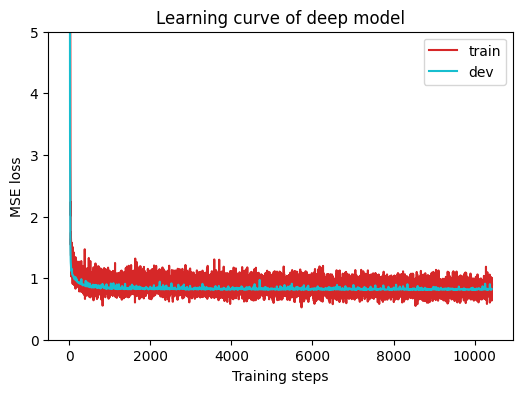

In [1118]:
# 绘制训练与验证损失曲线
plot_learning_curve(model_loss_record, title='deep model')

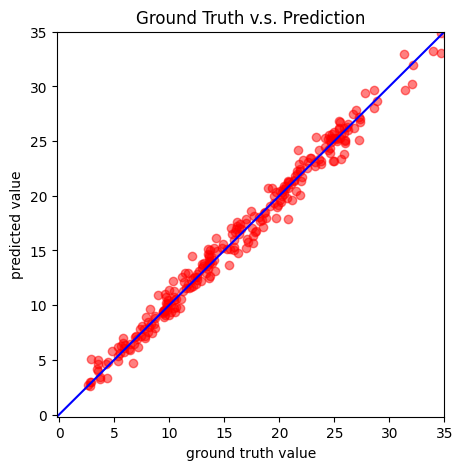

In [1119]:
# 显式删除变量引用并释放对象
# 清空训练时的模型，重新加载刚才训练过程中保存的最优模型权重（Best Checkpoint），并在验证集上绘制真实值与预测值的对比图。
del model
# 重新实例化一个新的、架构完全一样的空白神经网络，并把它送到指定设备（CPU 或 GPU）上。
model = NeuralNet(tr_set.dataset.dim).to(device)
# 从硬盘加载训练时通过 torch.save 保存下来的模型权重文件（即 config['save_path']，比如 models/model.pth）。
ckpt = torch.load(config['save_path'], map_location='cpu')
# 将加载进来的最优权重字典（包含各层的 w 和 b 数值）填入/灌入到新初始化的空白模型中。
model.load_state_dict(ckpt)
# 绘制预测值 vs 真实值散点图
plot_pred(dv_set, model, device)

# **测试**
用练好的最佳模型去预测测试集，并把结果导出为符合格式要求的 CSV 提交文件。   

In [1120]:
# 用练好的最佳模型去预测测试集，并把结果导出为符合格式要求的 CSV 提交文件。
def save_pred(preds, file):
  print('Saving results to {}'.format(file))
  with open(file, 'w') as fp:
    writer = csv.writer(fp)
    writer.writerow(['id', 'tested_positive'])
    for i, p in enumerate(preds):
        writer.writerow([i, p])

preds = test(tt_set, model, device)
save_pred(preds, 'pred.csv')

Saving results to pred.csv


In [1121]:
from google.colab import files
files.download('pred.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Hints**

## **Simple Baseline**
* Run sample code

## **Medium Baseline**
* Feature selection: 40 states + 2 `tested_positive` (`TODO` in dataset)

## **Strong Baseline**
* Feature selection (what other features are useful?)
* DNN architecture (layers? dimension? activation function?)
* Training (mini-batch? optimizer? learning rate?)
* L2 regularization
* There are some mistakes in the sample code, can you find them?

# **Reference**
This code is completely written by Heng-Jui Chang @ NTUEE.  
Copying or reusing this code is required to specify the original author.

E.g.  
Source: Heng-Jui Chang @ NTUEE (https://github.com/ga642381/ML2021-Spring/blob/main/HW01/HW01.ipynb)
